# Module 12 — Black-Box Optimisation

This notebook analyses the eight initial datasets, generates plots and proposes new input points using Gaussian Process regression and Expected Improvement. It loads the **extracted** `.npy` files from `data/initial_data/function_1` through `function_8` (no ZIP required). Save this notebook in `notebooks/` inside `module12_capstone_starter/`. Graphs are written to `images/` and proposed queries to `results/`. Run **Kernel → Restart & Run All** in Jupyter. The suggested points are exploratory, not guaranteed maxima; check input bounds before submission.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, qmc
from scipy.spatial.distance import cdist
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from pathlib import Path

# Supports launching Jupyter from notebooks/, the project root, or a parent folder.
cwd = Path.cwd()
possible_roots = [cwd, cwd.parent, cwd / "module12_capstone_starter", cwd / "stage-2-bbo/module-12/module12_capstone_starter"]
PROJECT_ROOT = next((p for p in possible_roots if (p / "data/initial_data/function_1/initial_inputs.npy").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f"Could not locate data/initial_data from {cwd}. Open Jupyter in the module12_capstone_starter/notebooks folder or project root.")
DATA_DIR = PROJECT_ROOT / "data" / "initial_data"
IMAGES_DIR = PROJECT_ROOT / "images"
RESULTS_DIR = PROJECT_ROOT / "results"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT.resolve())
print("Initial data:", DATA_DIR.resolve())


Project root: /Users/eestroci/Downloads/module12_capstone_starter
Initial data: /Users/eestroci/Downloads/module12_capstone_starter/data/initial_data


In [2]:
datasets = {}
for i in range(1, 9):
    folder = DATA_DIR / f"function_{i}"
    X = np.load(folder / "initial_inputs.npy")
    y = np.load(folder / "initial_outputs.npy").ravel()
    assert X.shape[0] == y.shape[0], f"Function {i}: input/output row mismatch"
    datasets[i] = (X, y)
    print(f"Function {i}: X={X.shape}, y={y.shape}, best={y.max():.6f}")


Function 1: X=(10, 2), y=(10,), best=0.000000
Function 2: X=(10, 2), y=(10,), best=0.611205
Function 3: X=(15, 3), y=(15,), best=-0.034835
Function 4: X=(30, 4), y=(30,), best=-4.025542
Function 5: X=(20, 4), y=(20,), best=1088.859618
Function 6: X=(20, 5), y=(20,), best=-0.714265
Function 7: X=(30, 6), y=(30,), best=1.364968
Function 8: X=(40, 8), y=(40,), best=9.598482


## Initial data visualisations

For 2D functions, the scatter plots show input coordinates coloured by observed output. For every function, an output-by-observation plot is generated. The dashed line indicates the highest observed value, not the true maximum.

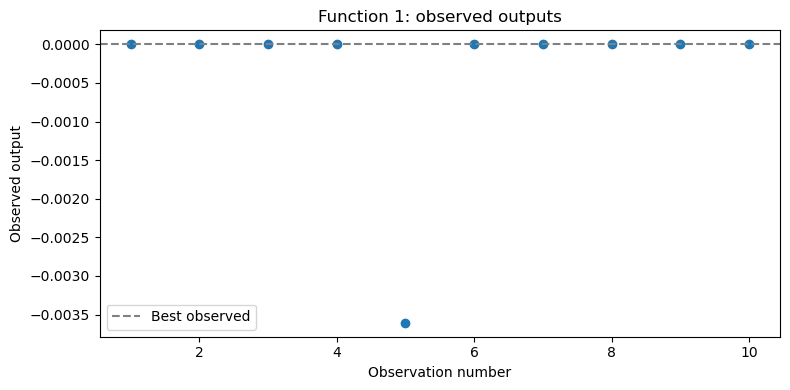

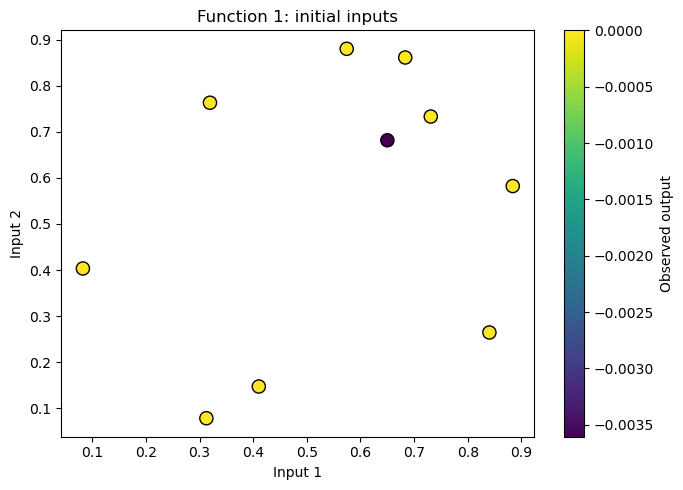

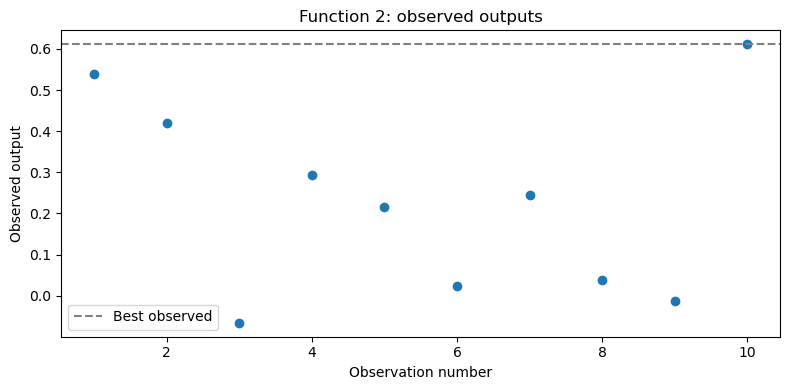

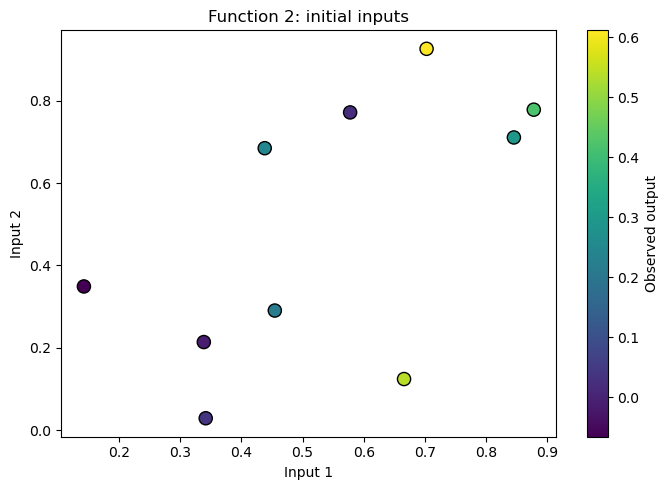

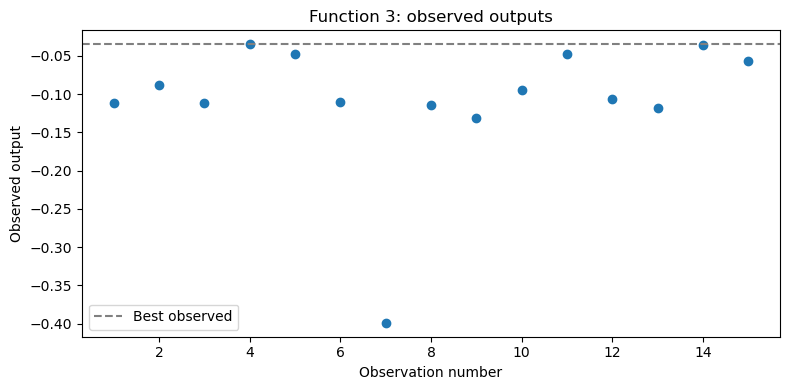

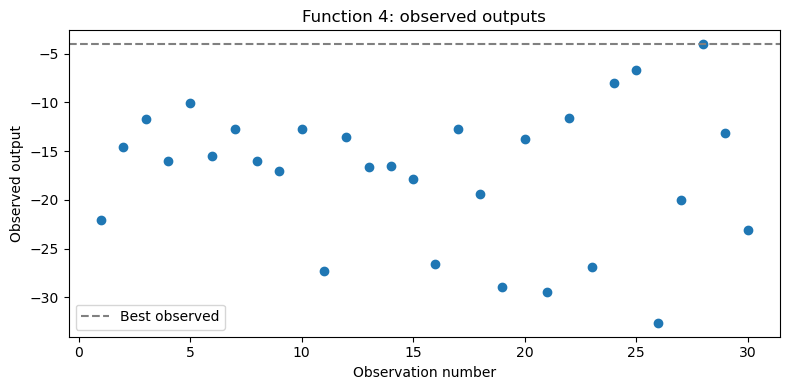

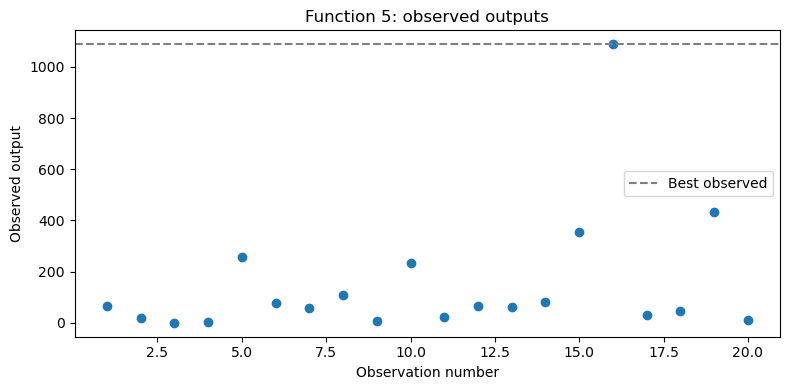

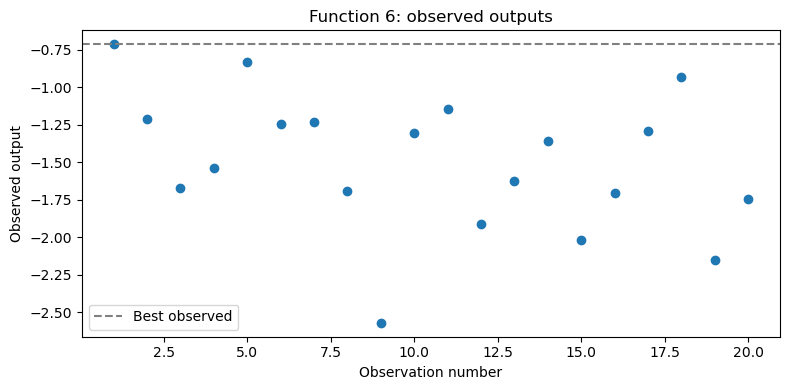

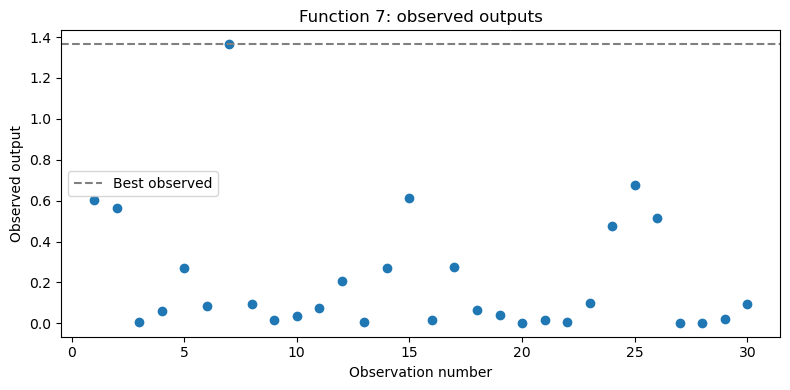

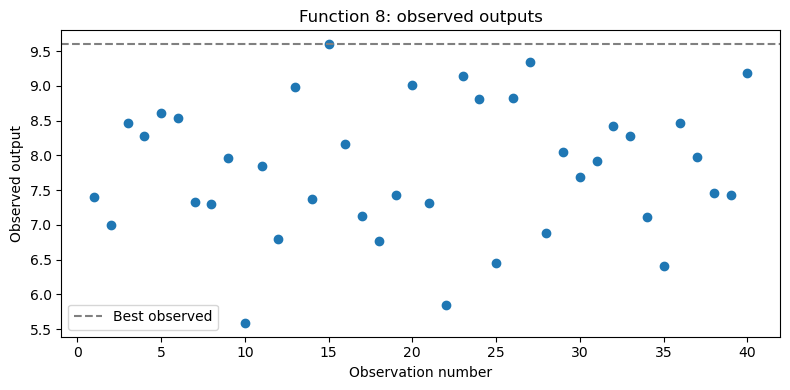

In [3]:
for i, (X, y) in datasets.items():
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(np.arange(1, len(y)+1), y)
    ax.axhline(y.max(), linestyle="--", color="gray", label="Best observed")
    ax.set(xlabel="Observation number", ylabel="Observed output", title=f"Function {i}: observed outputs")
    ax.legend()
    fig.tight_layout()
    fig.savefig(IMAGES_DIR / f"function_{i}_outputs.png", dpi=160)
    plt.show()
    if X.shape[1] == 2:
        fig, ax = plt.subplots(figsize=(7, 5))
        scatter = ax.scatter(X[:, 0], X[:, 1], c=y, s=90, edgecolor="black")
        fig.colorbar(scatter, ax=ax, label="Observed output")
        ax.set(xlabel="Input 1", ylabel="Input 2", title=f"Function {i}: initial inputs")
        fig.tight_layout()
        fig.savefig(IMAGES_DIR / f"function_{i}_inputs.png", dpi=160)
        plt.show()

## Bayesian optimisation: GP + Expected Improvement

Each output vector is standardised before GP fitting. We use a Matérn 5/2 covariance kernel and a small learned noise term. Sobol candidate points cover the unit hypercube. Expected Improvement (EI) balances high predicted outputs and predictive uncertainty. Candidate points too close to existing inputs are excluded. For higher-dimensional functions, GP estimates can be uncertain because data are sparse.

In [5]:
def expected_improvement(mu, sigma, best, xi=0.01):
    improvement = mu - best - xi
    z = improvement / np.maximum(sigma, 1e-12)
    return improvement * norm.cdf(z) + sigma * norm.pdf(z)

results = []
for i, (X, y) in datasets.items():
    d = X.shape[1]
    y_mean, y_scale = y.mean(), max(y.std(), 1e-8)
    y_scaled = (y-y_mean)/y_scale
    kernel = (ConstantKernel(1.0, (0.01, 100)) *
              Matern(length_scale=np.full(d, 0.25), length_scale_bounds=(0.04, 5), nu=2.5) +
              WhiteKernel(noise_level=0.01, noise_level_bounds=(1e-6, 0.5)))
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=2, random_state=42)
    gp.fit(X, y_scaled)
    candidates = qmc.Sobol(d, scramble=True, seed=123+i).random_base2(m=13)
    mean, sigma = gp.predict(candidates, return_std=True)
    ei = expected_improvement(mean, sigma, y_scaled.max())
    ei[cdist(candidates, X).min(axis=1) < 0.025] = 0
    j = int(np.argmax(ei))
    k = int(np.argmax(y))
    point = candidates[j]
    results.append({"function": i, "dimensions": d, "observations": len(y),
                    "best_observation": k+1, "best_output": float(y[k]),
                    "best_input": "-".join(f"{v:.6f}" for v in X[k]),
                    "proposed_query": "-".join(f"{v:.6f}" for v in point),
                    "predicted_mean": float(mean[j]*y_scale+y_mean),
                    "predicted_std": float(sigma[j]*y_scale),
                    "method": "Gaussian process Expected Improvement"})
results_df = pd.DataFrame(results)
display(results_df)
results_df.to_csv(RESULTS_DIR / "module12_query_points.csv", index=False)
print("Saved results to:", RESULTS_DIR / "module12_query_points.csv")

/usr/local/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.04. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified lower bound 0.04. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/anaconda3/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified upper bound 0.5. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/anaconda3/lib/python3.13/site-packages/sklearn/gaussi

,function,dimensions,observations,best_observation,best_output,best_input,proposed_query,predicted_mean,predicted_std,method
0,1,2,10,3,7.710875e-16,0.731024-0.733000,0.636532-0.870476,-0.000243,0.001049,Gaussian process Expected Improvement
1,2,2,10,10,6.112052e-01,0.702637-0.926564,0.702434-0.003860,0.602396,0.063763,Gaussian process Expected Improvement
2,3,3,15,4,-3.483531e-02,0.492581-0.611593-0.340176,0.049384-0.056136-0.000652,-0.063277,0.084343,Gaussian process Expected Improvement
3,4,4,30,28,-4.025542e+00,0.577766-0.428772-0.425826-0.249007,0.463444-0.442874-0.367822-0.437098,-1.926853,0.743110,Gaussian process Expected Improvement
4,5,4,20,16,1.088860e+03,0.224189-0.846480-0.879484-0.878516,0.128875-0.952909-0.993414-0.971871,1401.639503,124.515006,Gaussian process Expected Improvement
5,6,5,20,1,-7.142649e-01,0.728186-0.154693-0.732552-0.693997-0.056401,0.442232-0.279891-0.763812-0.969187-0.005849,-0.223573,0.266076,Gaussian process Expected Improvement
6,7,6,30,7,1.364968e+00,0.057896-0.491672-0.247422-0.218118-0.420428-0...,0.010192-0.114226-0.516979-0.232024-0.394805-0...,1.363787,0.071338,Gaussian process Expected Improvement
7,8,8,40,15,9.598482e+00,0.056447-0.065956-0.022929-0.038786-0.403935-0...,0.105367-0.197209-0.301906-0.048695-0.934135-0...,10.023353,0.232948,Gaussian process Expected Improvement


Saved results to: /Users/eestroci/Downloads/module12_capstone_starter/results/module12_query_points.csv


## Reflection prompts

- **Method:** Gaussian Process with Matérn kernel and Expected Improvement acquisition.
- **Exploration vs exploitation:** EI rewards both predicted improvement and uncertainty; in high dimensions predictions are less reliable.
- **What was learned:** Compare the new outputs with the initial best values and inspect whether predictions were accurate.
- **Next round:** Append the new input/output pairs to each dataset, refit the models and select new queries.

**Limitations:** The objective functions are unknown. The selected points are not guaranteed maxima. Model choices, input bounds and observed data quality influence the results. Avoid treating the predicted means as actual outcomes.